# 11 — OULAD statistical validation and real-world comparison

This notebook validates the OULAD evaluation population in two stages. First, it tests whether the latest OULAD presentation differs from the earlier presentations used as development context. Second, it compares cutoff-specific engagement measurements and selected-model metrics with the authorised KU Leuven Open Data, Private Learners release.

The unit of analysis is a student-course-presentation enrollment. P-values are inferential diagnostics for the observed samples; they do not establish causality, fairness, intervention benefit, or population representativeness. The model-metric comparison is descriptive because each dataset contributes one aggregate score per cutoff.

## Formal statistical protocol

The analysis uses alpha = 0.05 and Holm-Bonferroni correction within each family of tests. Numeric distribution comparisons report the two-sample Kolmogorov-Smirnov test, the Mann-Whitney U test, medians, quartiles, and Cliff's delta. Categorical comparisons use chi-square tests with Cramer's V. Binary outcome prevalence is compared with a two-row chi-square contingency test.

The latest OULAD presentation is treated as the comparison cohort and all earlier presentations are the reference cohort. At days 30, 60, and 90, VLE clicks, active days, distinct resources, and the derived daily-activity rate are compared with the 2021 KU Leuven locked-test cohort. These fields are proxies for recorded engagement, not direct measurements of study time or learning quality.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from pipeline.statistical_validation import run_oulad_statistical_validation

CUTOFFS = (30, 60, 90)
REPORT_PATH = PROJECT_ROOT / 'models' / 'validation' / 'oulad_statistical_validation.json'
report = run_oulad_statistical_validation(
    data_dir=PROJECT_ROOT / 'data' / 'processed' / 'oulad',
    kuleuven_path=PROJECT_ROOT / 'data' / 'raw' / 'external' / 'kuleuven' / 'dataset.zip',
    output=REPORT_PATH,
    cutoffs=CUTOFFS,
)
print(f"Saved measured report to {REPORT_PATH}")
print(f"Latest OULAD presentation: {report['latest_presentation']}")
print(f"Prior presentations: {', '.join(report['prior_presentations'])}")

Saved measured report to D:\AI PROJECTS\C++\Smart-Study-Planner\models\validation\oulad_statistical_validation.json
Latest OULAD presentation: 2014J
Prior presentations: 2013B, 2013J, 2014B


## 1. Temporal composition and risk-rate audit

A temporal holdout is useful only when the comparison cohort is described. The next tables show whether static enrollment characteristics and the binary risk rate changed between the earlier and latest presentations. A significant result is a warning that model performance may not transport unchanged across presentations; it is not a reason to infer a cause from the field.

In [2]:
internal = report['internal_temporal_validation']
static_numeric = pd.DataFrame(internal['numeric_distribution_tests'])
categorical = pd.DataFrame(internal['categorical_distribution_tests'])
risk_rate = pd.DataFrame([internal['risk_rate_test']])

print('Numeric temporal-shift tests')
display(static_numeric[['feature', 'reference_median', 'comparison_median', 'ks_statistic', 'ks_p_value_holm', 'cliffs_delta', 'ks_significant_005']])
print('Categorical temporal-shift tests')
display(categorical[['feature', 'category_count', 'p_value_holm', 'cramers_v', 'significant_005']])
print('Risk prevalence comparison')
display(risk_rate[['reference', 'comparison', 'reference_positive_rate', 'comparison_positive_rate', 'rate_difference_comparison_minus_reference', 'p_value']])

Numeric temporal-shift tests


,feature,reference_median,comparison_median,ks_statistic,ks_p_value_holm,cliffs_delta,ks_significant_005
0,num_of_prev_attempts,0.0,0.0,0.018496,0.025509,-0.018974,True
1,studied_credits,60.0,60.0,0.017706,0.025509,-0.001353,True


Categorical temporal-shift tests


,feature,category_count,p_value_holm,cramers_v,significant_005
0,gender,2,1.780025e-13,0.041965,True
1,region,13,5.021607e-11,0.048751,True
2,highest_education,5,3.124772e-07,0.034214,True
3,age_band,3,9.228458e-03,0.018167,True
4,disability,2,5.270465e-01,0.003504,False
5,code_module,7,1.403118e-283,0.202066,True


Risk prevalence comparison


,reference,comparison,reference_positive_rate,comparison_positive_rate,rate_difference_comparison_minus_reference,p_value
0,prior_presentations,2014J,0.534618,0.515364,-0.019254,0.00093


## 2. Cutoff-specific engagement shift

The same engagement fields are tested at each early-warning cutoff. Comparing the effect size across 30, 60, and 90 days helps distinguish a stable cohort difference from a cutoff-specific measurement artifact. Holm-adjusted p-values control the within-cutoff multiple-test family; Cliff's delta communicates practical direction and magnitude.

,cutoff_days,feature,reference_median,comparison_median,ks_p_value_holm,cliffs_delta,ks_significant_005
0,30,activity_count,189.00000,185.000000,1.857743e-04,0.002952,True
1,30,active_day_count,11.00000,11.000000,4.533342e-03,-0.008689,True
2,30,content_count,21.00000,21.000000,1.762708e-27,-0.027126,True
3,30,mean_daily_activity,15.80000,16.459936,8.995426e-04,0.022727,True
4,60,activity_count,284.00000,275.000000,1.263452e-03,-0.009061,True
5,60,active_day_count,18.00000,17.000000,2.584954e-06,-0.022059,True
6,60,content_count,26.00000,28.000000,5.361605e-29,-0.011892,True
7,60,mean_daily_activity,15.00000,15.500000,1.263452e-03,0.017494,True
8,90,activity_count,340.00000,324.000000,4.628873e-05,-0.017359,True
9,90,active_day_count,23.00000,21.000000,2.057678e-14,-0.040553,True


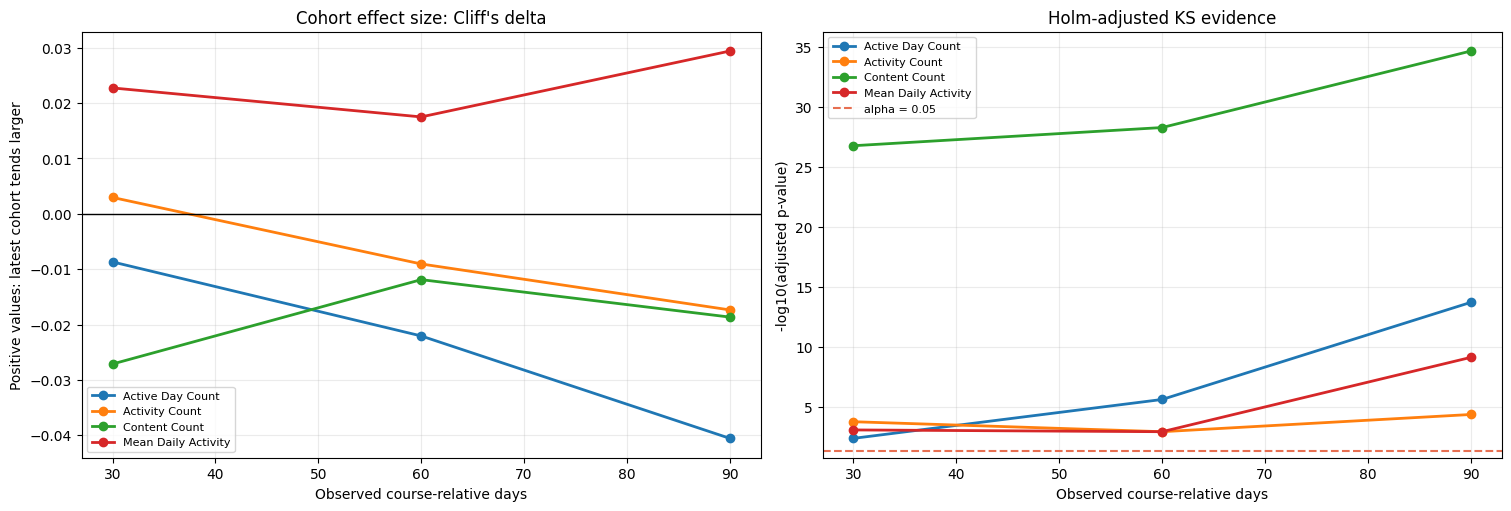

In [3]:
engagement_rows = []
for cutoff, rows in internal['engagement_distribution_tests_by_cutoff'].items():
    for row in rows:
        engagement_rows.append({'cutoff_days': int(cutoff), **row})
engagement = pd.DataFrame(engagement_rows)
display(engagement[['cutoff_days', 'feature', 'reference_median', 'comparison_median', 'ks_p_value_holm', 'cliffs_delta', 'ks_significant_005']])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for feature, group in engagement.groupby('feature'):
    group = group.sort_values('cutoff_days')
    axes[0].plot(group['cutoff_days'], group['cliffs_delta'], marker='o', linewidth=2, label=feature.replace('_', ' ').title())
    axes[1].plot(group['cutoff_days'], -np.log10(group['ks_p_value_holm'].clip(lower=1e-300)), marker='o', linewidth=2, label=feature.replace('_', ' ').title())
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title("Cohort effect size: Cliff's delta")
axes[0].set_ylabel('Positive values: latest cohort tends larger')
axes[1].axhline(-np.log10(0.05), color='#e76f51', linestyle='--', label='alpha = 0.05')
axes[1].set_title('Holm-adjusted KS evidence')
axes[1].set_ylabel('-log10(adjusted p-value)')
for axis in axes:
    axis.set_xlabel('Observed course-relative days')
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.show()

The plot is not a model leaderboard. A large negative or positive effect size means that the observed latest-presentation engagement distribution is shifted relative to the earlier presentations. A small p-value with a near-zero effect size can occur because OULAD contains many enrollments; the effect-size scale is therefore essential for interpretation.

## 3. Comparison with the authorised real-world KU Leuven release

The KU Leuven comparison uses its 2021 locked test cohort. The feature mapping is intentionally narrow: OULAD VLE clicks are compared with KU Leuven LMS actions, distinct dates with active days, and distinct VLE sites with content IDs. The fields are operational proxies collected by different systems, so significant differences are expected to indicate measurement or population shift rather than a universal student difference.

In [4]:
real_rows = []
for cutoff, rows in report['real_world_comparison']['numeric_distribution_tests_by_cutoff'].items():
    for row in rows:
        real_rows.append({'cutoff_days': int(cutoff), **row})
real_features = pd.DataFrame(real_rows)
display(real_features[['cutoff_days', 'feature', 'reference_median', 'comparison_median', 'ks_p_value_holm', 'cliffs_delta', 'ks_significant_005']])

rate_rows = []
for cutoff, row in report['real_world_comparison']['risk_rate_tests_by_cutoff'].items():
    rate_rows.append({'cutoff_days': int(cutoff), **row})
real_rates = pd.DataFrame(rate_rows)
display(real_rates[['cutoff_days', 'reference_positive_rate', 'comparison_positive_rate', 'rate_difference_comparison_minus_reference', 'p_value']])

,cutoff_days,feature,reference_median,comparison_median,ks_p_value_holm,cliffs_delta,ks_significant_005
0,30,activity_count,185.000000,384.000000,5.864967e-76,0.340913,True
1,30,active_day_count,11.000000,16.000000,1.247274e-92,0.246158,True
2,30,content_count,21.000000,47.000000,1.129689e-248,0.601771,True
3,30,mean_daily_activity,16.459936,25.133333,1.122389e-64,0.332579,True
4,60,activity_count,275.000000,800.000000,9.228435e-131,0.483456,True
5,60,active_day_count,17.000000,29.000000,2.732500e-114,0.333401,True
6,60,content_count,28.000000,73.000000,0.000000e+00,0.698053,True
7,60,mean_daily_activity,15.500000,30.484848,5.357957e-158,0.479670,True
8,90,activity_count,324.000000,1253.000000,2.927584e-206,0.588559,True
9,90,active_day_count,21.000000,40.000000,6.566439e-142,0.414273,True


,cutoff_days,reference_positive_rate,comparison_positive_rate,rate_difference_comparison_minus_reference,p_value
0,30,0.515364,0.364546,-0.150818,1.930390e-26
1,60,0.515364,0.364546,-0.150818,1.930390e-26
2,90,0.515364,0.364546,-0.150818,1.930390e-26


,dataset,cutoff_days,selected_model,pr_auc,roc_auc,balanced_accuracy,f1,brier_score
0,OULAD,30,hist_gradient_boosting,0.825576,0.802754,0.730635,0.735760,0.186244
1,OULAD,60,hist_gradient_boosting,0.870224,0.846169,0.761332,0.775719,0.168348
2,OULAD,90,hist_gradient_boosting,0.888122,0.864619,0.766858,0.784848,0.165973
3,KU Leuven,30,logistic_regression,0.540837,0.675425,0.590733,0.375522,0.220881
4,KU Leuven,60,logistic_regression,0.566409,0.698626,0.624696,0.467662,0.211388
5,KU Leuven,90,logistic_regression,0.605750,0.720735,0.643293,0.508876,0.200656


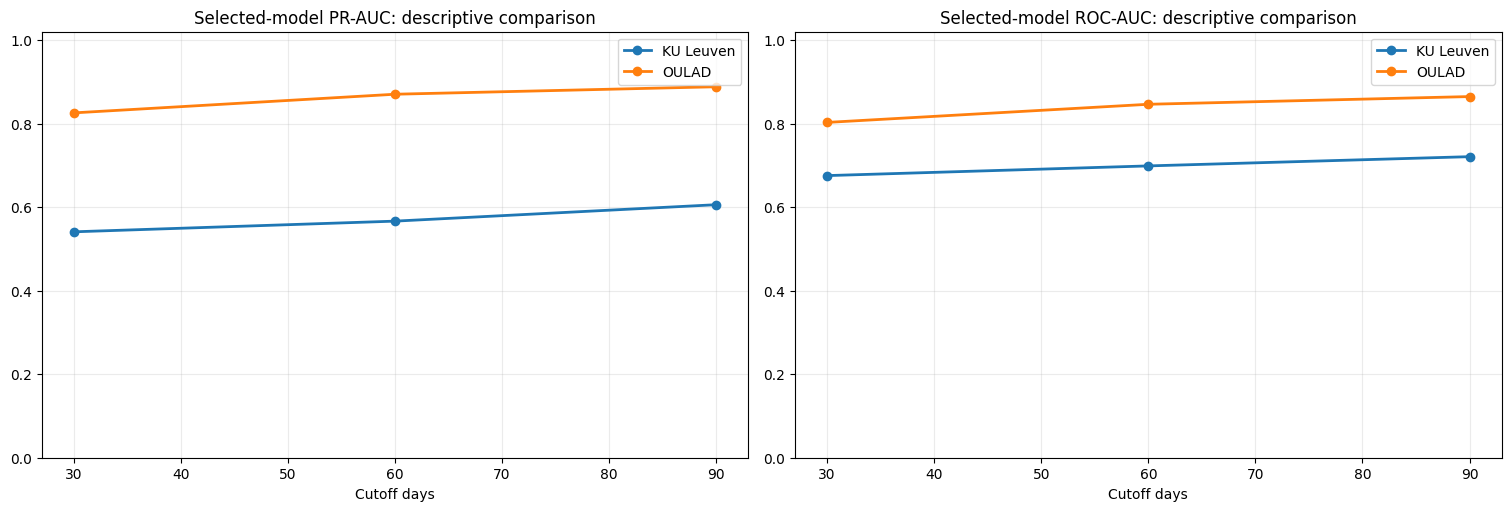

In [5]:
metric_table = pd.DataFrame(report['real_world_comparison']['selected_model_metric_comparison'])
display(metric_table[['dataset', 'cutoff_days', 'selected_model', 'pr_auc', 'roc_auc', 'balanced_accuracy', 'f1', 'brier_score']])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for dataset, group in metric_table.groupby('dataset'):
    group = group.sort_values('cutoff_days')
    axes[0].plot(group['cutoff_days'], group['pr_auc'], marker='o', linewidth=2, label=dataset)
    axes[1].plot(group['cutoff_days'], group['roc_auc'], marker='o', linewidth=2, label=dataset)
axes[0].set_title('Selected-model PR-AUC: descriptive comparison')
axes[1].set_title('Selected-model ROC-AUC: descriptive comparison')
for axis in axes:
    axis.set_xlabel('Cutoff days')
    axis.set_ylim(0, 1.02)
    axis.grid(alpha=0.25)
    axis.legend()
plt.show()

## Formal conclusion and limitations

This validation establishes a measured temporal-composition audit for OULAD and a real-world measurement comparison against KU Leuven. It does not convert the OULAD benchmark into prospective intervention evidence. The two datasets differ in institution, curriculum, LMS instrumentation, cohort composition, and outcome construction. The risk-rate and feature-distribution tests should therefore be used to guide robustness checks, calibration review, and subgroup analysis.

The selected-model metric table is intentionally descriptive. It does not attach a p-value to the difference between two aggregate PR-AUC or ROC-AUC values because a single summary score per dataset is not a valid replicate-level sample for such a test. A deployment decision still requires prospective validation, a reviewed alert policy, calibration, fairness review, and institutional approval.